# 03 — Classifier la gravité enregistrée des collisions

Objectif 1 uniquement : comparer douze configurations et analyser leurs erreurs. Exécuter le notebook 02, puis toutes les cellules de celui-ci. Les tableaux, matrices, importances et courbes sont calculés et affichés ici. L’exécution complète entraîne réellement les modèles et prend plusieurs minutes.


## 1. Bibliothèques et protocole

Train : 2021–2023 ; validation commune : 2024 ; test : 2025. Le F1 macro 2024 sélectionne la configuration parmi les douze candidats. Le poids de chaque classe est sa fréquence inverse à la puissance 0, 0,5 ou 1, calculée sur train. Les cas rares restent dans les données.

Médianes, standardisation et vocabulaire sont appris sur train seulement. Les 24 variables sont explicites : ni identifiant, ni année, ni nombre de victimes, ni information de gravité dans les prédicteurs. 2025 avait été inspecté dans les premiers essais du projet ; il est tenu hors de cette nouvelle sélection, sans être un audit prospectif vierge.


In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
from pathlib import Path
import gc
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, average_precision_score, log_loss,
    precision_recall_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, label_binarize
from threadpoolctl import threadpool_limits

LABELS=[1,2,3]
NAMES=['Mortelle','Grave','Légère']
SEED=42
from pathlib import Path
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "notebooks").is_dir() and (p / "requirements.txt").is_file()), None)
if ROOT is None: raise RuntimeError("Ouvrir ce notebook depuis le dossier road-safety-project ou son sous-dossier notebooks.")
RAW = ROOT / "data/raw"
PROCESSED = ROOT / "data/processed"
YEARS = [2021, 2022, 2023, 2024, 2025]
NUM_CONTEXT = ['hour_sin','hour_cos','month_sin','month_cos']
CAT_CONTEXT = ['speed_limit','day_of_week','first_road_class','road_type','light_conditions','weather_conditions','road_surface_conditions','urban_or_rural_area']
NUM_VEHICLES = ['vehicle_count','driver_age_min','driver_age_mean','vehicle_age_mean','young_driver_share','older_driver_share']
CAT_VEHICLES = ['has_cycle','has_motorcycle','has_car','has_goods','has_bus','has_ppt']

THREAD_LIMITER = threadpool_limits(limits=4)

from IPython.display import display


## 2. Charger la table issue du nettoyage

C’est un fichier de données, pas du code externe. Si le fichier manque, exécuter le notebook 02. Lecture des flottants en mode round-trip pour conserver les valeurs calculées pendant la préparation.


In [2]:
prepared_file = PROCESSED / "collision_severity_2021_2025.csv.gz"
if not prepared_file.exists(): raise FileNotFoundError("Exécuter d’abord 02_preparation_donnees.ipynb.")
frame = pd.read_csv(prepared_file, low_memory=False, float_precision="round_trip")
numeric = NUM_CONTEXT + NUM_VEHICLES
cat = CAT_CONTEXT + CAT_VEHICLES
features = numeric + cat
for field in cat: frame[field] = frame[field].fillna("MISSING").astype(str)
for field in numeric: frame[field] = pd.to_numeric(frame[field], errors="coerce")
train=frame.loc[frame.year.le(2023)].copy(); val=frame.loc[frame.year.eq(2024)].copy(); test=frame.loc[frame.year.eq(2025)].copy()
if set(train.collision_index)&set(val.collision_index) or set(train.collision_index)&set(test.collision_index) or set(val.collision_index)&set(test.collision_index): raise ValueError('Collision dans plusieurs partitions')
splits={name:{'rows':len(df),'class_counts':df.target.value_counts().sort_index().astype(int).to_dict()} for name,df in [('train',train),('validation',val),('test',test)]}
Xtr,ytr=train[features],train.target; Xv,yv=val[features],val.target

display(pd.DataFrame([{"Partition":name,"Lignes":item["rows"],"Mortelles":item["class_counts"].get(1,0),"Graves":item["class_counts"].get(2,0),"Légères":item["class_counts"].get(3,0)} for name,item in splits.items()]).set_index("Partition"))


,Lignes,Mortelles,Graves,Légères
Partition,,,,
train,311349,4598,68055,238696
validation,100927,1502,23567,75858
test,101525,1453,25191,74881


## 3. Grille exacte et prétraitement des modèles

La régression logistique et Extra Trees reçoivent une imputation numérique et un encodage OneHot ajustés sur train. Le gradient boosting reçoit des catégories ordinalement encodées mais explicitement déclarées catégorielles ; il gère nativement les numériques absents. L’intermédiaire `Pipeline` est défini ici, son code n’est pas caché dans un fichier Python.


In [3]:
def candidates():
    configs=[{'name':'dummy_prior','family':'dummy','weight_power':0}]
    for c,p in [(0.1,0),(1,0),(1,0.5),(1,1),(3,0.5)]:
        configs.append(dict(name=f'logistic_C{c}_w{p}',family='logistic',C=c,weight_power=p))
    for leaves,it,p in [(15,150,0),(31,220,0),(31,220,0.5),(15,300,1),(63,300,0.5)]:
        configs.append(dict(name=f'hgb_leaf{leaves}_iter{it}_w{p}',family='hgb',leaves=leaves,iterations=it,weight_power=p))
    configs.append(dict(name='extra_trees_160_w0.5',family='extra_trees',weight_power=0.5))
    return configs

display(pd.DataFrame(candidates()))


,name,family,weight_power,C,leaves,iterations
0,dummy_prior,dummy,0.0,NaN,NaN,NaN
1,logistic_C0.1_w0,logistic,0.0,0.1,NaN,NaN
2,logistic_C1_w0,logistic,0.0,1.0,NaN,NaN
3,logistic_C1_w0.5,logistic,0.5,1.0,NaN,NaN
4,logistic_C1_w1,logistic,1.0,1.0,NaN,NaN
5,logistic_C3_w0.5,logistic,0.5,3.0,NaN,NaN
6,hgb_leaf15_iter150_w0,hgb,0.0,NaN,15.0,150.0
7,hgb_leaf31_iter220_w0,hgb,0.0,NaN,31.0,220.0
8,hgb_leaf31_iter220_w0.5,hgb,0.5,NaN,31.0,220.0
9,hgb_leaf15_iter300_w1,hgb,1.0,NaN,15.0,300.0


In [4]:
def make_estimator(config,numeric,categorical):
    if config['family']=='dummy': return DummyClassifier(strategy='prior')
    if config['family']=='hgb':
        prep=ColumnTransformer([
            ('numeric','passthrough',numeric),
            ('categorical',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1,encoded_missing_value=-1),categorical),
        ],sparse_threshold=0)
        estimator=HistGradientBoostingClassifier(learning_rate=0.08,max_iter=config['iterations'],max_leaf_nodes=config['leaves'],min_samples_leaf=100,l2_regularization=2.0,early_stopping=False,categorical_features=[False]*len(numeric)+[True]*len(categorical),random_state=SEED)
    else:
        prep=ColumnTransformer([
            ('numeric',Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler())]),numeric),
            ('categorical',OneHotEncoder(handle_unknown='ignore',min_frequency=20),categorical),
        ])
        if config['family']=='logistic': estimator=LogisticRegression(C=config['C'],max_iter=1000,random_state=SEED)
        else: estimator=ExtraTreesClassifier(n_estimators=160,max_depth=24,min_samples_leaf=10,max_features=0.7,n_jobs=1,random_state=SEED)
    return Pipeline([('prepare',prep),('model',estimator)])

def fit_config(config,X,y,numeric,categorical):
    model=make_estimator(config,numeric,categorical)
    power=config.get('weight_power',0)
    if power:
        counts=y.value_counts(); weight=(len(y)/(len(counts)*y.map(counts)))**power
        weight=weight/weight.mean()
        model.fit(X,y,model__sample_weight=weight.to_numpy())
    else: model.fit(X,y)
    return model


In [5]:
# Contrôle ciblé : les transformations ne se réajustent pas à la prédiction.
check_X = pd.DataFrame({"age":[10.,20.,np.nan,40.,50.,60.], "road":["a","b","a","b","a","b"]})
check_y = pd.Series([1,1,2,2,3,3])
check_model = fit_config({"family":"logistic","C":1,"weight_power":0}, check_X, check_y, ["age"], ["road"])
check_numeric = check_model.named_steps["prepare"].named_transformers_["numeric"]
check_median = check_numeric.named_steps["imputer"].statistics_.copy()
check_probabilities = check_model.predict_proba(pd.DataFrame({"age":[np.nan,1e6],"road":["new","new"]}))
np.testing.assert_array_equal(check_median, check_numeric.named_steps["imputer"].statistics_)
assert np.isfinite(check_probabilities).all()
np.testing.assert_allclose(check_probabilities.sum(axis=1),1)
print("Contrôle du prétraitement sans réajustement : OK.")


Contrôle du prétraitement sans réajustement : OK.


## 4. Mesures de classification

Le F1 macro, la balanced accuracy et les résultats par classe permettent de comparer les modèles malgré le déséquilibre.


In [6]:
def metrics(y,pred,prob=None,weight=None):
    out={'accuracy':accuracy_score(y,pred,sample_weight=weight),
         'balanced_accuracy':balanced_accuracy_score(y,pred,sample_weight=weight),
         'macro_f1':f1_score(y,pred,labels=LABELS,average='macro',zero_division=0,sample_weight=weight)}
    if prob is not None:
        binary=label_binarize(y,classes=LABELS)
        out['macro_average_precision']=average_precision_score(binary,prob,average='macro',sample_weight=weight)
        out['log_loss']=log_loss(y,prob,labels=LABELS,sample_weight=weight)
        for j,label in enumerate(LABELS):
            out[f'ap_{label}']=average_precision_score((np.asarray(y)==label).astype(int),prob[:,j],sample_weight=weight)
    return out


## 5. Entraîner et comparer les douze configurations

Ce bloc réalise tous les `fit` sur 2021–2023 et toutes les comparaisons sur 2024. Le test n’intervient pas dans cette sélection. Tous les essais sont conservés, y compris les moins bons.


In [7]:
history=[]; best=None; best_config=None; best_score=-1
for i,config in enumerate(candidates()):
    print(f"{i+1}/{len(candidates())} {config['name']}",flush=True)
    t=time.perf_counter()
    with warnings.catch_warnings(record=True) as recorded:
        warnings.simplefilter('always')
        model=fit_config(config,Xtr,ytr,numeric,cat)
        prob=model.predict_proba(Xv); pred=model.predict(Xv)
    row=dict(name=config['name'],config=config,seconds=time.perf_counter()-t,**metrics(yv,pred,prob),warnings=list(dict.fromkeys(str(w.message) for w in recorded)))
    history.append(row)
    print(f"  F1 macro={row['macro_f1']:.4f}, BA={row['balanced_accuracy']:.4f}, {row['seconds']:.1f}s",flush=True)
    if config['family']!='dummy' and row['macro_f1']>best_score:
        best_score=row['macro_f1']; best=model; best_config=config
    else: del model
    gc.collect()
print('Modèle retenu : '+best_config['name'],flush=True)

validation = pd.DataFrame(history).sort_values("macro_f1", ascending=False)
display(validation[["name","macro_f1","balanced_accuracy","accuracy","seconds","warnings"]].round(4))
print("Choisi sur validation :", best_config)


1/12 dummy_prior
  F1 macro=0.2861, BA=0.3333, 0.0s
2/12 logistic_C0.1_w0
  F1 macro=0.3116, BA=0.3438, 9.3s
3/12 logistic_C1_w0
  F1 macro=0.3119, BA=0.3439, 9.5s
4/12 logistic_C1_w0.5
  F1 macro=0.3874, BA=0.3850, 13.7s
5/12 logistic_C1_w1
  F1 macro=0.3442, BA=0.5023, 17.7s
6/12 logistic_C3_w0.5
  F1 macro=0.3880, BA=0.3855, 12.0s
7/12 hgb_leaf15_iter150_w0
  F1 macro=0.3310, BA=0.3531, 9.8s
8/12 hgb_leaf31_iter220_w0
  F1 macro=0.3328, BA=0.3539, 14.8s
9/12 hgb_leaf31_iter220_w0.5
  F1 macro=0.4095, BA=0.4028, 14.5s
10/12 hgb_leaf15_iter300_w1
  F1 macro=0.3749, BA=0.5201, 16.6s
11/12 hgb_leaf63_iter300_w0.5
  F1 macro=0.4071, BA=0.3994, 22.5s
12/12 extra_trees_160_w0.5
  F1 macro=0.3943, BA=0.3889, 438.1s
Modèle retenu : hgb_leaf31_iter220_w0.5


,name,macro_f1,balanced_accuracy,accuracy,seconds,warnings
8,hgb_leaf31_iter220_w0.5,0.4095,0.4028,0.7326,14.5353,[]
10,hgb_leaf63_iter300_w0.5,0.4071,0.3994,0.7303,22.4742,[]
11,extra_trees_160_w0.5,0.3943,0.3889,0.7345,438.1483,[]
5,logistic_C3_w0.5,0.3880,0.3855,0.7370,11.9896,[]
3,logistic_C1_w0.5,0.3874,0.3850,0.7370,13.7382,[]
9,hgb_leaf15_iter300_w1,0.3749,0.5201,0.5332,16.6185,[]
4,logistic_C1_w1,0.3442,0.5023,0.4928,17.6705,[]
7,hgb_leaf31_iter220_w0,0.3328,0.3539,0.7567,14.7880,[]
6,hgb_leaf15_iter150_w0,0.3310,0.3531,0.7569,9.7808,[]
2,logistic_C1_w0,0.3119,0.3439,0.7540,9.5286,[]


Choisi sur validation : {'name': 'hgb_leaf31_iter220_w0.5', 'family': 'hgb', 'leaves': 31, 'iterations': 220, 'weight_power': 0.5}


## 6. Robustesse rétrospective et apport des véhicules

Le contrôle 2021–2022→2023 est rétrospectif : il utilise la configuration choisie avec 2024 et ne constitue donc pas un test prospectif indépendant. L’ablation garde seulement les variables de contexte pour mesurer l’apport des agrégats véhicules sur validation.


In [8]:
# Backtest is a robustness diagnostic; it does not replace the fixed 2024 selection rule.
early=frame.loc[frame.year.le(2022)]; later=frame.loc[frame.year.eq(2023)]
back_model=fit_config(best_config,early[features],early.target,numeric,cat)
backtest=metrics(later.target,back_model.predict(later[features]),back_model.predict_proba(later[features]));del back_model;gc.collect()
print('Ablation contexte seul...',flush=True)
ablation_model=fit_config(best_config,train[NUM_CONTEXT+CAT_CONTEXT],ytr,NUM_CONTEXT,CAT_CONTEXT)
ablation=metrics(yv,ablation_model.predict(val[NUM_CONTEXT+CAT_CONTEXT]),ablation_model.predict_proba(val[NUM_CONTEXT+CAT_CONTEXT]));del ablation_model;gc.collect()

display(pd.DataFrame({"Contrôle rétrospectif 2023":backtest,"Contexte seul sur validation":ablation}).round(4))


Ablation contexte seul...


,Contrôle rétrospectif 2023,Contexte seul sur validation
accuracy,0.7434,0.7358
balanced_accuracy,0.4033,0.3587
macro_f1,0.4104,0.3451
macro_average_precision,0.4323,0.3831
log_loss,0.6126,0.6642
ap_1,0.0596,0.0465
ap_2,0.3642,0.2866
ap_3,0.8732,0.8161


## 7. Effet de la quantité de données d’entraînement

Les sous-échantillons sont stratifiés par classe ; les scores restent calculés sur la validation 2024 commune.


In [9]:
print('Courbe de taille d’entraînement...',flush=True)
learning=[]
for fraction in [0.25,0.5]:
    subset=train.groupby('target',group_keys=False).sample(frac=fraction,random_state=SEED)
    lm=fit_config(best_config,subset[features],subset.target,numeric,cat)
    learning.append(dict(fraction=fraction,n=len(subset),**metrics(yv,lm.predict(Xv))));del lm;gc.collect()
learning.append(dict(fraction=1.0,n=len(train),**metrics(yv,best.predict(Xv))))

display(pd.DataFrame(learning).round(4))


Courbe de taille d’entraînement...


,fraction,n,accuracy,balanced_accuracy,macro_f1
0,0.25,77838,0.7270,0.3919,0.3987
1,0.50,155675,0.7296,0.3989,0.4059
2,1.00,311349,0.7326,0.4028,0.4095


## 8. Importance des variables sur validation

Échantillon proportionnel par classe d’environ 30 000 collisions ; cinq permutations par variable. La mesure est la baisse du F1 macro. Les variables corrélées peuvent partager leur importance ; les rangs ne prouvent pas une causalité.


In [10]:
print('Importance par permutation sur validation...',flush=True)
sample=val.groupby('target',group_keys=False).sample(frac=min(1.0,30000/len(val)),random_state=SEED)
pi=permutation_importance(best,sample[features],sample.target,scoring='f1_macro',n_repeats=5,random_state=SEED,n_jobs=1)
importance=[dict(feature=f,mean=float(m),std=float(s)) for f,m,s in zip(features,pi.importances_mean,pi.importances_std)]

display(pd.DataFrame(importance).sort_values("mean",ascending=False).round(4))


Importance par permutation sur validation...


,feature,mean,std
10,speed_limit,0.0245,0.0032
19,has_motorcycle,0.0218,0.0021
6,driver_age_mean,0.0160,0.0041
4,vehicle_count,0.0157,0.0017
14,light_conditions,0.0126,0.0013
17,urban_or_rural_area,0.0104,0.0022
21,has_goods,0.0097,0.0021
13,road_type,0.0064,0.0020
0,hour_sin,0.0063,0.0011
12,first_road_class,0.0054,0.0030


## 9. Fonctions d’incertitude et d’analyse des erreurs

Le bootstrap de Poisson utilise 1 000 répétitions au niveau collision, conditionnellement au modèle fixé. Il n’inclut pas toute l’incertitude de sélection. Les sous-groupes de moins de 500 collisions sont exclus des comparaisons affichées.


In [11]:
def confidence_intervals(y,pred,baseline_pred,groups,repetitions=1000):
    rng=np.random.default_rng(SEED)
    _,idx=np.unique(groups,return_inverse=True)
    n=int(idx.max())+1
    rows=[]
    for _ in range(repetitions):
        weights=rng.poisson(1,n)[idx]
        score=f1_score(y,pred,labels=LABELS,average='macro',zero_division=0,sample_weight=weights)
        base=f1_score(y,baseline_pred,labels=LABELS,average='macro',zero_division=0,sample_weight=weights)
        ba=balanced_accuracy_score(y,pred,sample_weight=weights)
        rows.append([score,ba,score-base])
    arr=np.asarray(rows)
    return {name:{'low':float(np.quantile(arr[:,i],0.025)),'high':float(np.quantile(arr[:,i],0.975))} for i,name in enumerate(['macro_f1','balanced_accuracy','macro_f1_gain_vs_dummy'])}

def group_analysis(test,pred):
    d=test.copy(); d['predicted']=pred
    d['vehicle_count_group']=pd.cut(d.vehicle_count,[0,1,2,1000],labels=['1','2','3+']).astype(str)
    records=[]
    for field in ['speed_group','urban_group','reporting_regime','vehicle_count_group','police_force']:
        for label,part in d.groupby(field,dropna=False):
            if len(part)<500: continue
            scores=metrics(part.target,part.predicted)
            report=classification_report(part.target,part.predicted,labels=LABELS,output_dict=True,zero_division=0)
            records.append(dict(group=field,value=str(label),n=len(part),**scores,fatal_precision=report['1']['precision'],fatal_recall=report['1']['recall'],fatal_support=report['1']['support']))
    return records


## 10. Évaluation sur 2025 du modèle déjà choisi

Le `predict` et les probabilités portent sur le test ; aucune méthode `fit` n’est appelée sur 2025. La référence majoritaire est ajustée sur train.


In [12]:
print('Évaluation du modèle fixé sur 2025...',flush=True)
if list(best.classes_) != LABELS: raise ValueError('Ordre des classes inattendu.')
Xt,yt=test[features],test.target
pred=best.predict(Xt);prob=best.predict_proba(Xt)
baseline=DummyClassifier(strategy='prior').fit(Xtr,ytr);dummy_pred=baseline.predict(Xt);dummy_prob=baseline.predict_proba(Xt)
print(classification_report(yt,pred,labels=LABELS,target_names=NAMES,zero_division=0,digits=4))


Évaluation du modèle fixé sur 2025...
              precision    recall  f1-score   support

    Mortelle     0.1308    0.0736    0.0942      1453
       Grave     0.4392    0.2312    0.3029     25191
      Légère     0.7726    0.9023    0.8324     74881

    accuracy                         0.7239    101525
   macro avg     0.4475    0.4024    0.4098    101525
weighted avg     0.6807    0.7239    0.6905    101525



In [13]:
test_scores = metrics(yt,pred,prob)
dummy_scores = metrics(yt,dummy_pred,dummy_prob)
display(pd.DataFrame({"Référence majoritaire":dummy_scores,"Modèle retenu":test_scores}).round(4))
class_scores = classification_report(yt,pred,labels=LABELS,target_names=NAMES,output_dict=True,zero_division=0)
display(pd.DataFrame({k:v for k,v in class_scores.items() if isinstance(v,dict)}).T.round(4))
intervals = confidence_intervals(yt,pred,dummy_pred,test.collision_index)
display(pd.DataFrame(intervals).T.round(4))
subgroups = pd.DataFrame(group_analysis(test,pred))
display(subgroups.loc[subgroups.group.ne("police_force")].round(4))
display(subgroups.loc[subgroups.group.eq("police_force")].sort_values("n",ascending=False).head(15).round(4))


,Référence majoritaire,Modèle retenu
accuracy,0.7376,0.7239
balanced_accuracy,0.3333,0.4024
macro_f1,0.2830,0.4098
macro_average_precision,0.3333,0.4292
log_loss,0.6336,0.6365
ap_1,0.0143,0.0658
ap_2,0.2481,0.3758
ap_3,0.7376,0.8460


,precision,recall,f1-score,support
Mortelle,0.1308,0.0736,0.0942,1453.0
Grave,0.4392,0.2312,0.3029,25191.0
Légère,0.7726,0.9023,0.8324,74881.0
macro avg,0.4475,0.4024,0.4098,101525.0
weighted avg,0.6807,0.7239,0.6905,101525.0


,low,high
macro_f1,0.4040,0.4156
balanced_accuracy,0.3976,0.4070
macro_f1_gain_vs_dummy,0.1210,0.1326


,group,value,n,accuracy,balanced_accuracy,macro_f1,fatal_precision,fatal_recall,fatal_support
0,speed_group,20 mph,20045,0.7658,0.3521,0.3402,0.0000,0.0000,103.0
1,speed_group,30 mph,49673,0.7375,0.3745,0.3753,0.1250,0.0070,428.0
2,speed_group,40 mph,8886,0.7092,0.4049,0.4131,0.2083,0.0305,164.0
3,speed_group,50 mph,4612,0.6908,0.4186,0.4241,0.0930,0.0702,114.0
4,speed_group,60 mph,12709,0.6285,0.4349,0.4359,0.1322,0.1362,470.0
5,speed_group,70 mph,5600,0.7196,0.4222,0.4225,0.1350,0.1552,174.0
6,urban_group,Rural,34373,0.6772,0.4279,0.4332,0.1290,0.1073,932.0
7,urban_group,Urban,67148,0.7478,0.3699,0.3701,0.1628,0.0134,521.0
8,reporting_regime,0,13677,0.7637,0.4401,0.4528,0.1739,0.1143,210.0
9,reporting_regime,1,87848,0.7177,0.3973,0.4030,0.1221,0.0668,1243.0


,group,value,n,accuracy,balanced_accuracy,macro_f1,fatal_precision,fatal_recall,fatal_support
35,police_force,Metropolitan Police,20692,0.7939,0.3589,0.3595,0.2000,0.0108,93.0
52,police_force,West Midlands,4738,0.7847,0.3719,0.3769,0.3333,0.0238,42.0
42,police_force,Police Scotland,4104,0.5943,0.4100,0.3979,0.1728,0.1111,126.0
53,police_force,West Yorkshire,3895,0.7009,0.3762,0.3753,0.4000,0.0408,49.0
27,police_force,Hampshire,3503,0.7257,0.4247,0.4311,0.0690,0.0571,35.0
30,police_force,Kent,3417,0.7027,0.3913,0.3944,0.0323,0.0238,42.0
48,police_force,Sussex,3252,0.6977,0.4026,0.4020,0.0333,0.0500,20.0
49,police_force,Thames Valley,3007,0.7512,0.4176,0.4313,0.1905,0.0755,53.0
23,police_force,Essex,2877,0.6955,0.4063,0.4131,0.1154,0.0600,50.0
19,police_force,Devon and Cornwall,2833,0.7437,0.4438,0.4376,0.1176,0.1250,48.0


## 11. Graphiques de l’analyse

Les graphiques suivants affichent les résultats dans le notebook : comparaison sur validation, confusion sur test, précision–rappel et importance des variables. Ils sont destinés à l’interprétation statistique.


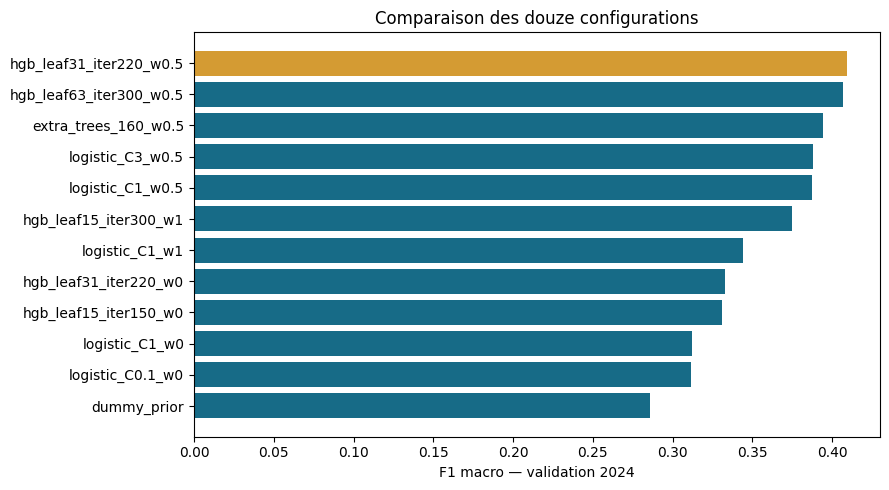

In [14]:
comparison = pd.DataFrame(history).sort_values("macro_f1")
fig,ax = plt.subplots(figsize=(9,5))
ax.barh(comparison.name,comparison.macro_f1,color=["#D49B33" if name==best_config["name"] else "#176B87" for name in comparison.name])
ax.set_xlabel("F1 macro — validation 2024")
ax.set_title("Comparaison des douze configurations")
plt.tight_layout()
plt.show()


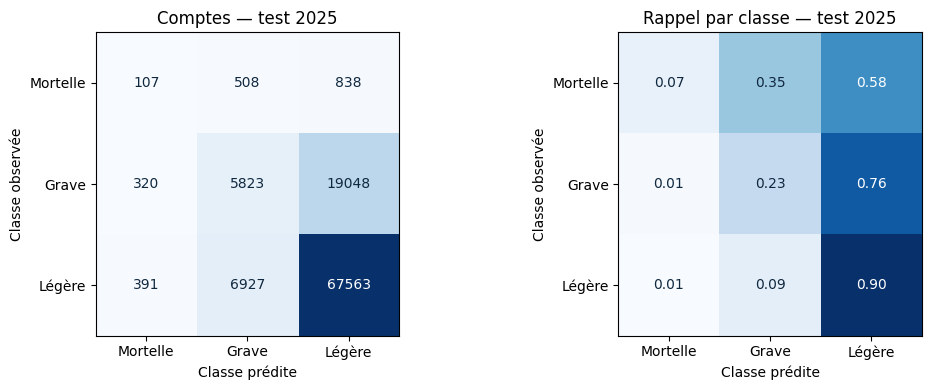

In [15]:
cm = confusion_matrix(yt,pred,labels=LABELS)
normalized = cm/cm.sum(axis=1,keepdims=True)
fig,axes = plt.subplots(1,2,figsize=(11,4))
for ax,values,title in zip(axes,[cm,normalized],["Comptes — test 2025","Rappel par classe — test 2025"]):
    ax.imshow(values,cmap="Blues")
    ax.set(xticks=range(3),yticks=range(3),xticklabels=NAMES,yticklabels=NAMES,xlabel="Classe prédite",ylabel="Classe observée",title=title)
    for i in range(3):
        for j in range(3):
            text = str(int(values[i,j])) if title.startswith("Comptes") else f"{values[i,j]:.2f}"
            ax.text(j,i,text,ha="center",va="center",color="white" if values[i,j]>values.max()/2 else "#10283F")
plt.tight_layout()
plt.show()


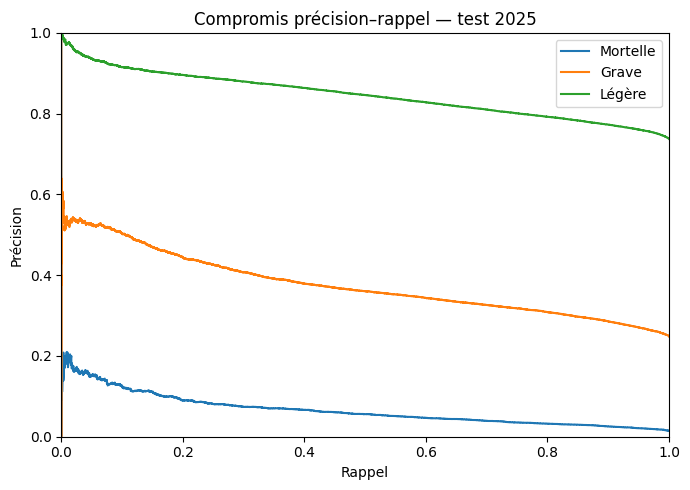

In [16]:
fig,ax = plt.subplots(figsize=(7,5))
for j,name in enumerate(NAMES):
    precision,recall,_ = precision_recall_curve(yt.eq(LABELS[j]).astype(int),prob[:,j])
    ax.plot(recall,precision,label=name)
ax.set(xlabel="Rappel",ylabel="Précision",xlim=(0,1),ylim=(0,1),title="Compromis précision–rappel — test 2025")
ax.legend()
plt.tight_layout()
plt.show()


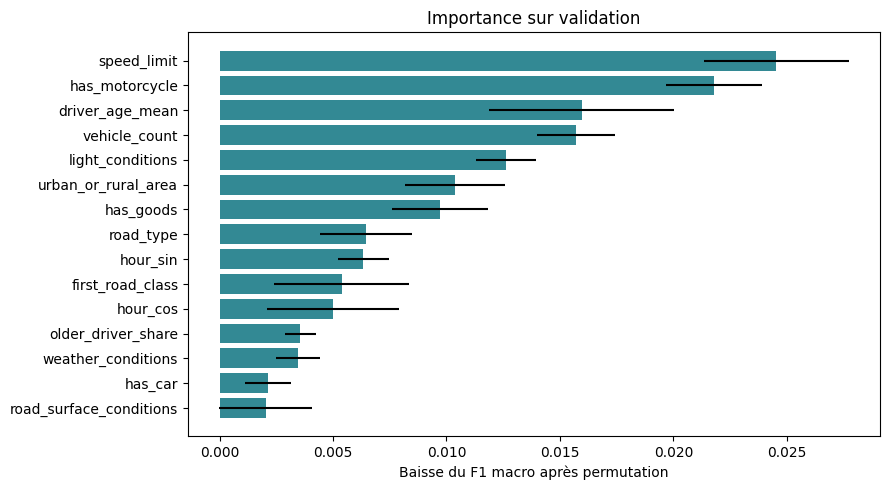

In [17]:
feature_importance = pd.DataFrame(importance).sort_values("mean").tail(15)
fig,ax = plt.subplots(figsize=(9,5))
ax.barh(feature_importance.feature,feature_importance["mean"],xerr=feature_importance["std"],color="#338994")
ax.set(xlabel="Baisse du F1 macro après permutation",title="Importance sur validation")
plt.tight_layout()
plt.show()


## Interpréter les résultats

Comparer le F1 macro à la référence et lire la précision, le rappel et le F1 de chaque classe. La classe mortelle reste difficile à prédire ; une accuracy globale élevée ne suffit pas. Les poids favorisant les classes rares changent le compromis entre fausses alertes et détections.

L’importance par permutation mesure la dépendance de ce modèle aux variables ; elle ne prouve pas une cause et peut se répartir entre variables corrélées. Le contrôle 2023 est rétrospectif, avec une configuration choisie en 2024.

Les données sont conditionnelles à une collision corporelle déclarée à la police. Les changements de déclaration des blessures affectent la gravité. 2025 a été inspecté dans les premiers essais du projet ; une future année indépendante sera nécessaire avant une validation externe.

[Source DfT](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data) · [Gravité DfT](https://www.gov.uk/government/publications/guide-to-severity-adjustments-for-reported-road-casualty-statistics) · [Prétraitement sans fuite](https://scikit-learn.org/stable/common_pitfalls).
